# 26. Mechanical engineering: tolerance stack-up and inspection

**Track:** core example &nbsp;·&nbsp; **Uses:** Chapters 3, 10, 12 and 18

**Reading:** Taylor, ch. 3.3–3.6 · Creveling, *Tolerance Design* ·
Bryan (1979) · ISO 14253-1

A product is assembled from parts that are never exactly their nominal
size. The designer must decide how much each dimension may vary, its
**tolerance**, so that the assembly still works. This is error propagation
run in reverse: instead of asking how uncertain a result is, one asks how
variable the inputs may be. The three standard methods of tolerance
analysis correspond exactly to three ideas of this book:

* **worst case**: add the tolerances, the "upper bound" of Taylor, ch. 3.3;
* **root sum of squares (RSS)**: add in quadrature, as for independent
  random errors (Section 3.2);
* **Monte Carlo**: simulate the manufacturing process (Chapter 10).

The example compares them on a shaft assembly, and then turns to the other
side of the problem: the measurement that decides whether an assembly
passes inspection has its own uncertainty, including a geometric error that
a careless set-up can make dominant.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

try:
    import errprop as ep
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import errprop as ep

ep.use_style()
rng = np.random.default_rng(126)

## The assembly

A housing of internal length $L_H$ holds a stack of five parts on a shaft: a
bearing, a spacer, a gear, a second bearing and a circlip. The axial gap
that remains,

$$ g = L_H - (L_1 + L_2 + L_3 + L_4 + L_5) , $$

must lie between 0.10 and 0.50 mm: a smaller gap risks binding when the
parts expand, a larger one lets the gear move. All sensitivity coefficients
are $\pm1$.

In [2]:
names = ["housing", "bearing 1", "spacer", "gear", "bearing 2", "circlip"]
nominal = np.array([50.30, 15.00, 10.00, 9.50, 15.00, 0.50])     # mm
tol = np.array([0.10, 0.04, 0.05, 0.05, 0.04, 0.03])             # ± mm
sign = np.array([+1, -1, -1, -1, -1, -1])
LSL, USL = 0.10, 0.50

g_nom = sign @ nominal
wc = np.sum(tol)
rss = np.sqrt(np.sum(tol**2))
print(f"nominal gap {g_nom:.2f} mm, specification {LSL:.2f} to {USL:.2f} mm")
print(f"worst case: {g_nom:.2f} ± {wc:.2f} mm  ->  {g_nom - wc:.2f} to {g_nom + wc:.2f} mm")
print(f"RSS:        {g_nom:.2f} ± {rss:.3f} mm  ->  {g_nom - rss:.3f} to {g_nom + rss:.3f} mm")

nominal gap 0.30 mm, specification 0.10 to 0.50 mm
worst case: 0.30 ± 0.31 mm  ->  -0.01 to 0.61 mm
RSS:        0.30 ± 0.138 mm  ->  0.162 to 0.438 mm


By the worst-case method the design fails: if every part were at the
unfavourable end of its tolerance, the gap could close completely or reach
0.61 mm. By RSS it passes with room to spare. The two answers differ by a
factor of two in the predicted spread, and the choice between them is a
question about the parts, not about arithmetic.

The worst case can occur, but it requires every part to be at an extreme
at the same time. RSS assumes the deviations are independent and random,
and in its usual form that each tolerance equals three standard deviations
of a normal, centred process (a process capability $C_p = 1$). Whether that
describes the factory is the real question. Monte Carlo simulation answers
it for any assumed process:

1. **RSS assumptions**: each dimension normal, centred, $\sigma = t/3$;
2. **uniform**: each dimension anywhere within its tolerance with equal
   probability, $\sigma = t/\sqrt3$, as when parts are sorted by a go/no-go
   gauge from a wider process;
3. **shifted**: normal with $\sigma = t/3$, but with each process mean
   shifted by $1.5\sigma$ in the direction that reduces the gap (the
   "1.5-sigma shift" conventionally allowed for slow process drift).

In [3]:
n_mc = 400_000
def simulate(kind, rng):
    if kind == "RSS assumptions":
        x = nominal + rng.normal(0, tol / 3, (n_mc, tol.size))
    elif kind == "uniform":
        x = nominal + rng.uniform(-tol, tol, (n_mc, tol.size))
    else:
        x = nominal - sign * 1.5 * tol / 3 + rng.normal(0, tol / 3, (n_mc, tol.size))
    return x @ sign

scenarios = ["RSS assumptions", "uniform", "shifted"]
gaps = {k: simulate(k, rng) for k in scenarios}
print("scenario           mean gap   sd      yield     Cpk     out of spec (ppm)")
for k in scenarios:
    g = gaps[k]
    mu, sd = g.mean(), g.std()
    yld = np.mean((g >= LSL) & (g <= USL))
    cpk = min(USL - mu, mu - LSL) / (3 * sd)
    print(f"{k:17s}  {mu:6.3f}   {sd:6.4f}   {yld:7.4f}   {cpk:5.2f}   {1e6 * (1 - yld):8.0f}")

scenario           mean gap   sd      yield     Cpk     out of spec (ppm)
RSS assumptions     0.300   0.0461    1.0000    1.45         20
uniform             0.300   0.0798    0.9937    0.83       6337
shifted             0.145   0.0461    0.8355    0.33     164540


Under the RSS assumptions the yield is essentially 100 %: the RSS
prediction is right, *given its assumptions*. If the parts are uniformly
distributed within their tolerances, the spread is $\sqrt3$ times larger
and about six assemblies in a thousand fail; the central limit theorem
(Section 5.4) makes the gap nearly normal anyway, so the shape of the
individual distributions hardly matters, only their standard deviations.
With mean shifts, the yield falls further, because shifts of all parts in
the same direction add *linearly*, like the worst case, not in quadrature.
The process capability index
$C_{pk} = \min(\mathrm{USL} - \mu, \mu - \mathrm{LSL})/3\sigma$ summarises each
case; industry commonly requires $C_{pk} \ge 1.33$.

The lesson matches the one about systematic errors in measurement: random,
independent variations add in quadrature, common biases add linearly
(Section 16.1). RSS is justified for independent, centred processes;
worst case is the right tool for small production runs, for safety-critical
fits, and whenever the parts may share a bias.

## Where to spend money: the variance budget

Which tolerance should be tightened? Since all sensitivities are $\pm1$, each
part's share of the variance of the gap is its share of $\sum\sigma_i^2$
(Section 18.1).

In [4]:
var_share = tol**2 / np.sum(tol**2)
for nm, t, v in zip(names, tol, var_share):
    print(f"  {nm:10s}  ± {t:.2f} mm   variance share {v:5.1%}")
tol2 = tol.copy(); tol2[0] = 0.05
print(f"housing tolerance halved: RSS spread ± {np.sqrt(np.sum(tol2**2)):.3f} mm (was ± {rss:.3f})")

  housing     ± 0.10 mm   variance share 52.4%
  bearing 1   ± 0.04 mm   variance share  8.4%
  spacer      ± 0.05 mm   variance share 13.1%
  gear        ± 0.05 mm   variance share 13.1%
  bearing 2   ± 0.04 mm   variance share  8.4%
  circlip     ± 0.03 mm   variance share  4.7%
housing tolerance halved: RSS spread ± 0.108 mm (was ± 0.138)


The housing alone contributes more than half of the variance. Halving its
tolerance reduces the spread of the gap by about a fifth; halving any
other tolerance would achieve far less.

## Inspecting the gap: the Abbe error

Assemblies are checked by measuring the gap, and that measurement has its
own uncertainty. One geometric error deserves special attention because it
is easy to create and invisible in repeated readings. In a caliper, the
scale lies along the beam, while the jaws touch the part a distance $h$
away, the **Abbe offset**. If the moving jaw tilts by a small angle
$\theta$ (play in its guide), the point of contact moves by $h\sin\theta$
relative to the scale reading (Bryan 1979). Abbe's principle states that
the scale should lie on the line of measurement, $h = 0$.

A clean way to find such errors is to follow the **kinematic chain** from
the scale to the point of contact with homogeneous transformation matrices,
as is done for measuring machines (Zhang et al. 2019 analyse a rotor
assembly machine this way). In two dimensions, the contact point is the
scale position $x$, followed by a rotation by $\theta$ of the jaw, followed
by the offset $h$ along the jaw:

$$ \begin{pmatrix} x_c \\ y_c \\ 1\end{pmatrix} =
   \begin{pmatrix} 1 & 0 & x \\ 0 & 1 & 0 \\ 0 & 0 & 1\end{pmatrix}
   \begin{pmatrix} \cos\theta & -\sin\theta & 0 \\ \sin\theta & \cos\theta & 0 \\ 0 & 0 & 1\end{pmatrix}
   \begin{pmatrix} 0 \\ h \\ 1\end{pmatrix} ,
   \qquad x_c = x - h\sin\theta . $$

The error of the measured length is $-h\sin\theta$. The cell propagates an
angular play $\theta$, uniform within ±0.5 mrad, linearly and by Monte Carlo
for several offsets $h$, and also evaluates the error that remains when the
measurement axis is not parallel to the gap by an angle $\varphi$, the
second-order **cosine error** $g(1/\cos\varphi - 1)$.

In [5]:
def contact_x(x, theta, h):
    T = np.array([[1, 0, x], [0, 1, 0], [0, 0, 1.0]])
    R = np.array([[np.cos(theta), -np.sin(theta), 0], [np.sin(theta), np.cos(theta), 0], [0, 0, 1.0]])
    return (T @ R @ np.array([0, h, 1.0]))[0]

theta_lim = 0.5e-3                                    # rad, play of the jaw (uniform ±)
u_theta = theta_lim / np.sqrt(3)
x_read = 0.30                                         # mm, the scale reading for a gap of 0.3 mm
h_values = np.array([0.0, 2.0, 5.0, 10.0, 20.0, 30.0, 40.0])   # mm
u_lin, u_mc, bias_mc = [], [], []
theta_s = rng.uniform(-theta_lim, theta_lim, 200_000)
for h in h_values:
    _, u = ep.propagate(lambda x, th: contact_x(x, th, h), [x_read, 0.0], u=[0.0, u_theta])
    err = x_read - h * np.sin(theta_s) - x_read            # vectorised form of contact_x - x
    u_lin.append(u); u_mc.append(err.std()); bias_mc.append(err.mean())
for h, ul, um in zip(h_values, u_lin, u_mc):
    print(f"Abbe offset h = {h:4.0f} mm: standard uncertainty from the jaw play  linear {1e3 * ul:5.2f} µm,  Monte Carlo {1e3 * um:5.2f} µm")
phi = rng.uniform(-10e-3, 10e-3, 200_000)                 # misalignment up to ±10 mrad
cos_err = x_read * (1 / np.cos(phi) - 1)
print(f"cosine error for misalignment within ±10 mrad: mean {1e6 * cos_err.mean():.3f} nm, max {1e6 * cos_err.max():.3f} nm")

Abbe offset h =    0 mm: standard uncertainty from the jaw play  linear  0.00 µm,  Monte Carlo  0.00 µm
Abbe offset h =    2 mm: standard uncertainty from the jaw play  linear  0.58 µm,  Monte Carlo  0.58 µm
Abbe offset h =    5 mm: standard uncertainty from the jaw play  linear  1.44 µm,  Monte Carlo  1.44 µm
Abbe offset h =   10 mm: standard uncertainty from the jaw play  linear  2.89 µm,  Monte Carlo  2.88 µm
Abbe offset h =   20 mm: standard uncertainty from the jaw play  linear  5.77 µm,  Monte Carlo  5.76 µm
Abbe offset h =   30 mm: standard uncertainty from the jaw play  linear  8.66 µm,  Monte Carlo  8.65 µm
Abbe offset h =   40 mm: standard uncertainty from the jaw play  linear 11.55 µm,  Monte Carlo 11.53 µm
cosine error for misalignment within ±10 mrad: mean 4.996 nm, max 15.000 nm


The Abbe error grows in proportion to the offset; with the 30 mm offset of
an ordinary caliper and a jaw play of ±0.5 mrad, it contributes a standard
uncertainty near 9 µm, more than the resolution of the instrument. Linear
propagation is exact here because the error is linear in $\theta$ to first
order. The cosine error, by contrast, has zero first-order sensitivity at
$\varphi = 0$, so linear propagation would report no uncertainty at all
(Section 12.3); Monte Carlo shows a small positive bias, but for a short gap
it amounts to a few nanometres, about a thousand times less than the Abbe
term. The practical rule follows Abbe: put the scale
in line with the measurement, or keep the offset small, as in a micrometer
or a depth gauge.

## Accept or reject? Decisions with measurement uncertainty

The inspection budget combines the resolution of a digital caliper (0.01 mm,
rectangular), the repeatability of placing it (4 µm), and the Abbe term for
$h = 30$ mm.

In [6]:
u_res = 0.010 / np.sqrt(12)
u_rep = 0.004
u_abbe = u_lin[list(h_values).index(30.0)]
u_meas = np.sqrt(u_res**2 + u_rep**2 + u_abbe**2)
print(f"inspection uncertainty: resolution {1e3 * u_res:.1f} µm, repeatability {1e3 * u_rep:.1f} µm,"
      f" Abbe {1e3 * u_abbe:.1f} µm  ->  u = {1e3 * u_meas:.1f} µm, U (k=2) = {2e3 * u_meas:.0f} µm")

inspection uncertainty: resolution 2.9 µm, repeatability 4.0 µm, Abbe 8.7 µm  ->  u = 10.0 µm, U (k=2) = 20 µm


When a measured gap falls just inside a limit, the true gap may lie just
outside it. Two errors are possible: a **false accept** (a bad assembly
passes) and a **false reject** (a good one fails). ISO 14253-1 protects the
customer by default: conformity is proved only if the measured value lies
inside the specification by at least the expanded uncertainty $U$, a
**guard band**. The cell simulates inspection of the "uniform" production
with acceptance limits moved inwards by a guard band of 0 to $2U$.

In [7]:
g_true = gaps["uniform"]
g_meas = g_true + rng.normal(0, u_meas, g_true.size)
good = (g_true >= LSL) & (g_true <= USL)
U = 2 * u_meas
bands = np.linspace(0, 2 * U, 9)
fa, fr = [], []
for gb in bands:
    accept = (g_meas >= LSL + gb) & (g_meas <= USL - gb)
    fa.append(np.mean(accept & ~good)); fr.append(np.mean(~accept & good))
fa, fr = np.array(fa), np.array(fr)
print(f"actually out of specification: {np.mean(~good):.2%}")
for gb, a, r in zip(bands, fa, fr):
    print(f"guard band {1e3 * gb:5.1f} µm: false accepts {1e6 * a:6.0f} ppm, false rejects {r:6.2%}")

actually out of specification: 0.63%
guard band   0.0 µm: false accepts   1065 ppm, false rejects  0.19%
guard band   5.0 µm: false accepts    568 ppm, false rejects  0.34%
guard band  10.0 µm: false accepts    208 ppm, false rejects  0.56%
guard band  14.9 µm: false accepts     62 ppm, false rejects  0.85%
guard band  19.9 µm: false accepts     22 ppm, false rejects  1.18%
guard band  24.9 µm: false accepts      5 ppm, false rejects  1.61%
guard band  29.9 µm: false accepts      0 ppm, false rejects  2.11%
guard band  34.9 µm: false accepts      0 ppm, false rejects  2.69%
guard band  39.9 µm: false accepts      0 ppm, false rejects  3.36%


Without a guard band, about a thousand assemblies per million that are out
of specification are accepted. A guard band of $U$ cuts the false accepts
about fifty-fold, at the cost of rejecting about 1 % of good assemblies
instead of 0.2 %. The trade-off is economic: the cost of a defect delivered
against the cost of scrapping a good part. It also shows the value of a
better measurement: reducing the Abbe offset to 5 mm would reduce $U$, and
with it both kinds of error.

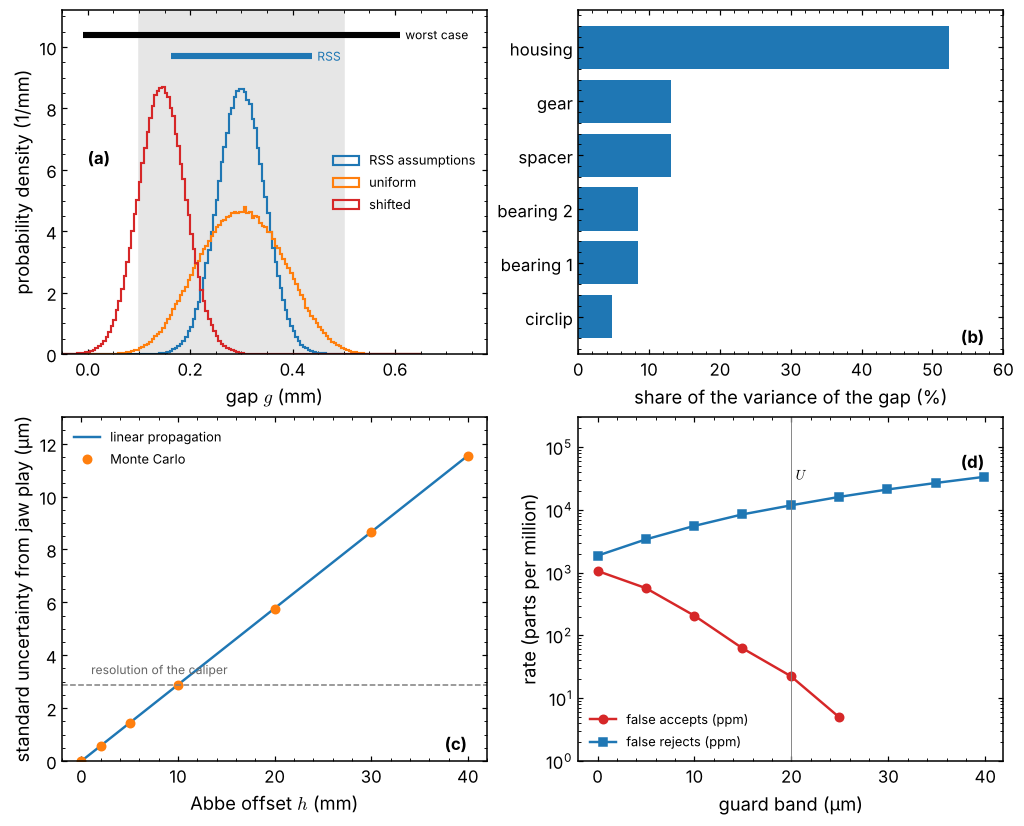

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.4))

ax = axes[0, 0]
bins = np.linspace(-0.05, 0.65, 141)
for k, c in zip(scenarios, ("C0", "C1", "C3")):
    ax.hist(gaps[k], bins, density=True, histtype="step", lw=1.4, color=c, label=k)
ax.axvspan(LSL, USL, color="0.9", zorder=0)
ax.hlines(10.4, g_nom - wc, g_nom + wc, color="k", lw=4)
ax.hlines(9.7, g_nom - rss, g_nom + rss, color="C0", lw=4)
ax.text(g_nom + wc + 0.01, 10.4, "worst case", fontsize=8, va="center")
ax.text(g_nom + rss + 0.01, 9.7, "RSS", fontsize=8, va="center", color="C0")
ax.set_xlabel("gap $g$ (mm)"); ax.set_ylabel("probability density (1/mm)")
ax.set_xlim(-0.05, 0.78); ax.set_ylim(0, 11.2); ax.legend(loc="center right", fontsize=8.5)
ep.panel_label(ax, "(a)", x=0.06, y=0.6)

ax = axes[0, 1]
order = np.argsort(var_share)
ax.barh(np.array(names)[order], 100 * var_share[order], color="C0")
ax.set_xlabel("share of the variance of the gap (%)")
ax.set_xlim(0, 60); ep.panel_label(ax, "(b)", x=0.9, y=0.08)

ax = axes[1, 0]
ax.plot(h_values, 1e3 * np.array(u_lin), "C0-", label="linear propagation")
ax.plot(h_values, 1e3 * np.array(u_mc), "o", color="C1", label="Monte Carlo")
ax.axhline(1e3 * u_res, color="0.5", ls="--", lw=1)
ax.text(1, 1e3 * u_res + 0.4, "resolution of the caliper", fontsize=8, color="0.4")
ax.set_xlabel("Abbe offset $h$ (mm)"); ax.set_ylabel("standard uncertainty from jaw play (µm)")
ax.set_ylim(0, 13); ax.legend(loc="upper left", fontsize=8.5); ep.panel_label(ax, "(c)", x=0.9, y=0.08)

ax = axes[1, 1]
pos = fa > 0
ax.semilogy(1e3 * bands[pos], 1e6 * fa[pos], "o-", color="C3", label="false accepts (ppm)")
ax.semilogy(1e3 * bands, 1e6 * fr, "s-", color="C0", label="false rejects (ppm)")
ax.axvline(1e3 * U, color="0.5", lw=0.6)
ax.text(1e3 * U + 0.5, 3e4, "$U$", fontsize=9)
ax.set_xlabel("guard band (µm)"); ax.set_ylabel("rate (parts per million)")
ax.set_ylim(1, 3e5); ax.legend(loc="lower left", fontsize=8.5); ep.panel_label(ax, "(d)", x=0.9, y=0.9)
plt.show()

**(a)** Simulated distributions of the gap for three assumptions about
manufacturing; shaded: the specification; bars at the top: worst-case and
RSS ranges. **(b)** Share of each part in the variance of the gap. **(c)**
Uncertainty of a caliper reading caused by jaw play, against the Abbe
offset; dashed: the contribution of the resolution. **(d)** False-accept and
false-reject rates at inspection against the guard band; vertical line: the
expanded uncertainty $U$.

## What this example teaches

* Worst-case and RSS tolerancing are the two extreme rules for combining
  errors, linear and quadrature, and the choice between them is a judgement
  about independence and centring of the processes.
* Monte Carlo replaces that judgement by an explicit model of the
  manufacturing process, including non-normal distributions and mean shifts.
* A variance budget tells where tightening a tolerance pays.
* The inspection measurement belongs in the analysis. Geometric errors such
  as the Abbe error are found by following the kinematic chain, and
  decisions near a limit need a guard band of the expanded uncertainty.

## References

* J. B. Bryan, "The Abbé principle revisited: an updated interpretation",
  *Precis. Eng.* **1**, 129 (1979).
* C. M. Creveling, *Tolerance Design: A Handbook for Developing Optimal
  Specifications* (Addison-Wesley, 1997).
* ISO 14253-1:2017, *Geometrical product specifications (GPS) — Inspection
  by measurement of workpieces and measuring equipment — Part 1: Decision
  rules for verifying conformity or nonconformity with specifications*
  (International Organization for Standardization, Geneva).
* D. C. Montgomery, *Introduction to Statistical Quality Control*, 7th ed.
  (Wiley, 2012).
* M. Zhang, Y. Liu, C. Sun, X. Wang and J. Tan, "Measurements error
  propagation and its sensitivity analysis in the aero-engine multistage
  rotor assembling process", *Rev. Sci. Instrum.* **90**, 115003 (2019).

## Exercises

1. Find, by Monte Carlo, the largest common tolerance multiplier for which
   the "shifted" process still has $C_{pk} \ge 1.33$.
2. Replace the uniform distribution of the housing by a triangular one.
   How much does the yield change, and why so little?
3. Extend the kinematic chain with a second rotation, a tilt of the part
   itself by $\psi$. Which combination of $\theta$, $\psi$ and $h$ gives the
   leading error?
4. Repeat the guard-band study with an Abbe offset of 5 mm. By how much do
   the false rejects at a guard band of $U$ fall?

---

**Previous:** [25. Analytical chemistry: a calibration curve and its detection limit](25_calibration_curve_detection_limit.ipynb)